# Ricochet: EDA real-time контура

Этот ноутбук проверяет новый слой `src/ricochet/reallife/` на синтетическом
потоке Netcool и **симулирует отсутствующую инфраструктуру**: брокер сообщений,
колоночное хранилище и горячий путь инцидента. Настоящие Kafka/Vector и
ClickHouse здесь заменены локальными классами с тем же контрактом:

```text
Netcool events -> MiniKafka -> MiniClickHouse -> intensity/EWMA
                                               -> HDBSCAN clusters
                                               -> lagged-PC causal graph
                                               -> XGBoost/эвристика -> runbook
```

Цель — не измерить абсолютную производительность Python-симулятора, а проверить
контракты, найти ошибки интеграции и показать, какие данные понадобятся
production-адаптеру.


## 1. Окружение и настройки

Ноутбук ищет корень проекта по наличию `src/ricochet` и `README.md`, поэтому его
можно запускать из корня или из `docs/`.


In [1]:
import json
import math
import sys
import tempfile
import time
from collections import defaultdict
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src" / "ricochet").exists():
    for p in [ROOT, *ROOT.parents]:
        if (p / "src" / "ricochet").exists() and (p / "README.md").exists():
            ROOT = p
            break
sys.path.insert(0, str(ROOT / "src"))

from ricochet.api.main import create_app
from ricochet.config import AppConfig
from ricochet.precheck.runbooks import RunbookRegistry
from ricochet.ranking import PairRanker, RankerConfig
from ricochet.reallife import (
    CausalConfig,
    ClusterConfig,
    IncidentBundleIn,
    MaintenanceWindowIn,
    RealtimeAlarm,
    RunbookAgent,
    RunbookConfig,
    TopologyEdgeIn,
    build_causal_graph,
    cluster_series,
    prepare_incident,
)
from ricochet.reallife.pipeline import series_id

plt.rcParams.update({
    "figure.figsize": (12, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
C_MAIN, C_ALT, C_WARN, C_OK = "#16161a", "#ffc800", "#c62828", "#2e7d32"

print("ROOT:", ROOT)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__)


ROOT: C:\Users\OEVLANNIKOV\Ricochet
Python: 3.12.2 | pandas: 3.0.6 | numpy: 2.5.4


## 2. Синтетический поток Netcool

Сажаем управляемый каскад:

- `A = ipcore | Huawei NE-Series | mplsTunnelRerouted` — причина;
- `B = ipcore | Juniper | RPD-ISIS-ADJ` — следствие через 20 секунд;
- `C = ipcore | Cisco | LDP-5-NBRCHG` — следствие через 40 секунд;
- `D = dcim | power | tempHigh` — независимый шум;
- дубль `nokia | dryContactAlarm` ↔ `alu | externalAlarm` на общих устройствах.

В середине окна вырезаем три минуты, чтобы проверить, что интенсивность
заполняется нулями, а EWMA затухает, а не рвётся.


In [2]:
START = datetime(2026, 1, 1, 12, 0)
STEP = 10
DURATION = 1800
GAP_START, GAP_END = 600, 780
rng = np.random.default_rng(42)


def at(seconds):
    return START + timedelta(seconds=seconds)


def add(rows, sec, integration, system, alert_group, node, alias, region, severity=4):
    rows.append(dict(
        ts=at(sec), integration=integration, system=system,
        alert_group=alert_group, node=node, node_alias=alias,
        region=region, severity=severity,
    ))


rows = []
for burst in range(0, DURATION - 60, 60):
    amp = int(rng.integers(3, 8))
    t0 = burst + int(rng.integers(0, 8))
    for _ in range(amp):
        jitter = int(rng.integers(0, 5))
        add(rows, t0 + jitter, "ipcore", "Huawei NE-Series", "mplsTunnelRerouted",
            "pe1.msk", "pe1", "MSK")
        add(rows, t0 + 20 + jitter, "ipcore", "Juniper", "RPD-ISIS-ADJ",
            "pe2.msk", "pe2", "MSK")
        add(rows, t0 + 40 + jitter, "ipcore", "Cisco", "LDP-5-NBRCHG",
            "pe3.msk", "pe3", "MSK")

for t in range(0, DURATION, 90):
    for k in range(int(rng.integers(1, 4))):
        add(rows, t + int(rng.integers(0, 20)), "dcim", "power", "tempHigh",
            "p1.spb", "p1", "SPB", severity=3)

for t in range(0, DURATION, 120):
    for alias in ("d1.msk", "d2.msk"):
        add(rows, t, "nsp", "nokia", "dryContactAlarm", alias, alias.split(".")[0], "MSK")
        add(rows, t + 10, "transport", "alu", "externalAlarm", alias, alias.split(".")[0], "MSK")

stream = pd.DataFrame(rows).sort_values("ts").reset_index(drop=True)
gap_mask = (stream["ts"] >= at(GAP_START)) & (stream["ts"] < at(GAP_END))
stream_gap = stream.loc[~gap_mask].copy()

print(f"alarms: {len(stream):,}  |  after simulated gap: {len(stream_gap):,}")
print(f"window: {stream_gap['ts'].min()} .. {stream_gap['ts'].max()}")
display(stream_gap.groupby(["integration", "system", "alert_group"]).size().to_frame("events"))


alarms: 523  |  after simulated gap: 480
window: 2026-01-01 12:00:00 .. 2026-01-01 12:28:46


events
integration system           alert_group               
dcim        power            tempHigh                35
ipcore      Cisco            LDP-5-NBRCHG           131
            Huawei NE-Series mplsTunnelRerouted     131
            Juniper          RPD-ISIS-ADJ           131
nsp         nokia            dryContactAlarm         26
transport   alu              externalAlarm           26

## 3. Симуляция Kafka и ClickHouse

`MiniKafka` хранит батчи в памяти и считает lag. `MiniClickHouse` принимает
батчи и умеет строить 10-секундную интенсивность так же, как production SQL.
Это не замена инфраструктуре, но проверяет границы ответственности и формат
данных, который потом уйдёт в реальные адаптеры.


In [3]:
class MiniKafka:
    def __init__(self):
        self.topics = defaultdict(list)
        self.consumed = defaultdict(int)

    def produce(self, topic, records):
        self.topics[topic].extend(dict(r) for r in records)

    def consume(self, topic, max_records=250):
        buf = self.topics[topic]
        batch = buf[:max_records]
        del buf[:len(batch)]
        self.consumed[topic] += len(batch)
        return batch

    def lag(self, topic):
        return len(self.topics[topic])


class MiniClickHouse:
    """In-memory stand-in for ClickHouse: raw rows + 10s aggregate query."""
    def __init__(self):
        self.rows = []
        self.df = pd.DataFrame()

    def insert(self, records):
        self.rows.extend(records)
        self.df = pd.DataFrame(self.rows)

    def count(self):
        return len(self.rows)

    def query_alarms(self, start, end):
        if self.df.empty:
            return self.df.copy()
        return self.df[(self.df["ts"] >= start) & (self.df["ts"] < end)].copy()

    def query_intensity(self, start, end, step_seconds=STEP):
        d = self.query_alarms(start, end)
        if d.empty:
            return pd.DataFrame(columns=["bucket", "integration", "system", "alert_group", "intensity"])
        d = d.copy()
        d["bucket"] = d["ts"].dt.floor(f"{step_seconds}s")
        return (d.groupby(["bucket", "integration", "system", "alert_group"], sort=False)
                .size().reset_index(name="intensity"))


kafka = MiniKafka()
clickhouse = MiniClickHouse()
TOPIC = "netcool.alarms"
batch_size = 250
for offset in range(0, len(stream_gap), batch_size):
    kafka.produce(TOPIC, stream_gap.iloc[offset:offset + batch_size].to_dict("records"))

# Горячий путь не обязан вычитывать всё сразу: проверяем lag и догоняем поток.
for _ in range(2):
    clickhouse.insert(kafka.consume(TOPIC, batch_size))
lag_after_two_batches = kafka.lag(TOPIC)
while kafka.lag(TOPIC) > 0:
    clickhouse.insert(kafka.consume(TOPIC, batch_size))

print("kafka lag after 2 batches:", lag_after_two_batches)
print("kafka lag after drain:", kafka.lag(TOPIC))
print("clickhouse rows:", clickhouse.count(), "of", len(stream_gap))
assert clickhouse.count() == len(stream_gap), "Kafka/ClickHouse simulation lost alarms"


kafka lag after 2 batches: 0
kafka lag after drain: 0
clickhouse rows: 480 of 480


## 4. Единый pipeline: интенсивность, EWMA, дыры

Собираем `IncidentBundle` из того, что вернул бы ClickHouse, и проверяем
математические свойства: размер матрицы, нули в вырезанном окне, затухание EWMA.


In [4]:
def bundle_from_frame(frame, incident_id="INC-RT-EDA"):
    alarms = [
        RealtimeAlarm(
            ts=row.ts.to_pydatetime(), integration=row.integration, system=row.system,
            alert_group=row.alert_group, node=row.node, node_alias=row.node_alias,
            region=row.region, severity=int(row.severity),
        )
        for row in frame.itertuples(index=False)
    ]
    return IncidentBundleIn(
        incident_id=incident_id,
        region="MSK",
        start=START,
        end=at(DURATION),
        alarms=alarms,
        topology_edges=[
            TopologyEdgeIn(source="pe1", target="pe2", relation="link"),
            TopologyEdgeIn(source="pe2", target="pe3", relation="link"),
        ],
        maintenance=[MaintenanceWindowIn(
            start=at(GAP_START), end=at(GAP_END), region="MSK",
            note="simulated collector gap")],
    )


bundle = bundle_from_frame(stream_gap)
prepared = prepare_incident(bundle, step_seconds=STEP, ewma_half_life_seconds=30)
print("series:", len(prepared.keys), "| bins:", len(prepared.grid),
      "| ewma alpha:", prepared.ewma_alpha)
print("warnings:", prepared.warnings)
display(prepared.intensity.head(3))
display(prepared.ewma.head(3))

gap_slice = prepared.intensity.loc[
    (prepared.intensity.index >= at(GAP_START)) &
    (prepared.intensity.index < at(GAP_END))
]
print("gap bins:", len(gap_slice), "| non-zero cells in gap:", int((gap_slice > 0).sum().sum()))
assert len(gap_slice) > 0
assert int((gap_slice > 0).sum().sum()) == 0, "intensity must be zero when there are no alarms"


series: 6 | bins: 181 | ewma alpha: 0.206299
warnings: []


,dcim|power|tempHigh,ipcore|Cisco|LDP-5-NBRCHG,ipcore|Huawei NE-Series|mplsTunnelRerouted,ipcore|Juniper|RPD-ISIS-ADJ,nsp|nokia|dryContactAlarm,transport|alu|externalAlarm
2026-01-01 12:00:00,1.0,0.0,3.0,0.0,2.0,0.0
2026-01-01 12:00:10,1.0,0.0,0.0,0.0,0.0,2.0
2026-01-01 12:00:20,0.0,0.0,0.0,3.0,0.0,0.0


,dcim|power|tempHigh,ipcore|Cisco|LDP-5-NBRCHG,ipcore|Huawei NE-Series|mplsTunnelRerouted,ipcore|Juniper|RPD-ISIS-ADJ,nsp|nokia|dryContactAlarm,transport|alu|externalAlarm
2026-01-01 12:00:00,1.000000,0.0,3.000000,0.000000,2.000000,0.000000
2026-01-01 12:00:10,1.000000,0.0,2.381102,0.000000,1.587401,0.412599
2026-01-01 12:00:20,0.793701,0.0,1.889882,0.618898,1.259921,0.327480


gap bins: 18 | non-zero cells in gap: 0


## 5. Тесты и визуализация сигналов

Ниже — небольшой test-runner: он не останавливает ноутбук при падении, а собирает
таблицу PASS/FAIL. Это удобно для EDA и для регрессионных прогонов.


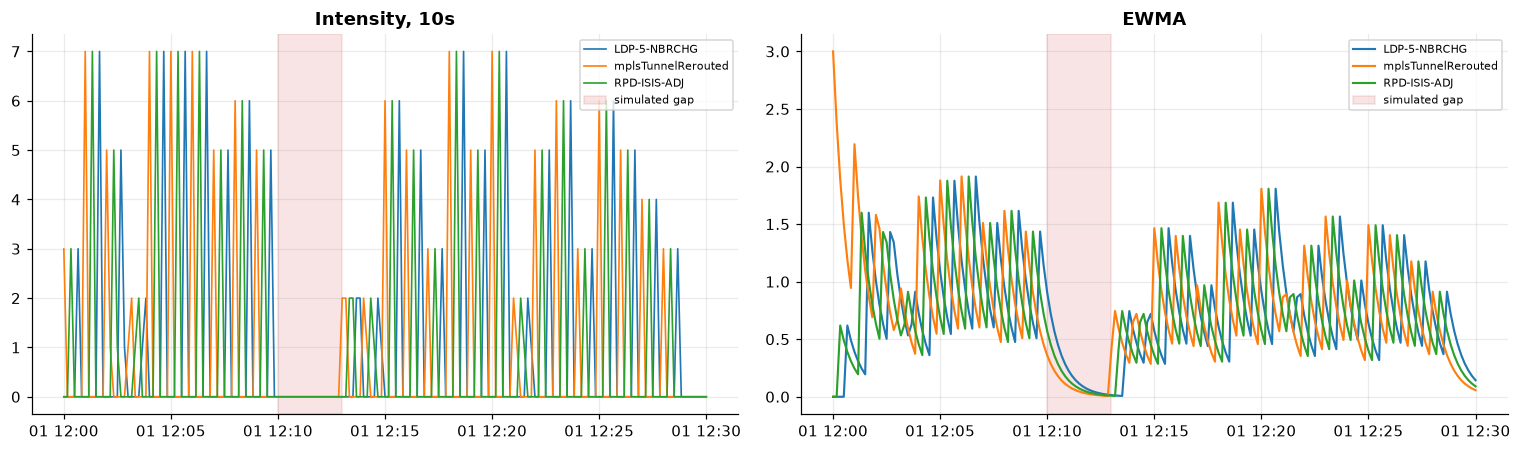

,check,status,detail
0,Kafka/ClickHouse без потерь,PASS,480 rows
1,Интенсивность: нули в дыре,PASS,18 bins
2,EWMA: сглаживание не превышает пик,PASS,max=3.000


In [5]:
CHECKS = []


def check(name, fn):
    try:
        detail = fn() or ""
        CHECKS.append(dict(check=name, status="PASS", detail=detail))
    except Exception as exc:
        CHECKS.append(dict(check=name, status="FAIL", detail=f"{type(exc).__name__}: {exc}"))


check("Kafka/ClickHouse без потерь", lambda: f"{clickhouse.count()} rows")
check("Интенсивность: нули в дыре", lambda: f"{len(gap_slice)} bins")
check("EWMA: сглаживание не превышает пик", lambda: f"max={prepared.ewma.to_numpy().max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ids = [series_id(k) for k in prepared.keys]
show = [sid for sid in ids if sid in {"ipcore|Huawei NE-Series|mplsTunnelRerouted",
                                       "ipcore|Juniper|RPD-ISIS-ADJ",
                                       "ipcore|Cisco|LDP-5-NBRCHG"}] or ids[:3]
for sid in show:
    axes[0].plot(prepared.intensity.index, prepared.intensity[sid], lw=1.1, label=sid.split("|")[-1])
    axes[1].plot(prepared.ewma.index, prepared.ewma[sid], lw=1.4, label=sid.split("|")[-1])
for ax, title in zip(axes, ["Intensity, 10s", "EWMA"]):
    ax.axvspan(at(GAP_START), at(GAP_END), color=C_WARN, alpha=0.12, label="simulated gap")
    ax.set_title(title)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

display(pd.DataFrame(CHECKS))


## 6. Causal graph

Строим ориентированный ациклический граф по EWMA-сигналам. Для теста отключаем
снятие общего фактора (мало рядов) и conditioning set, чтобы проверить сам
контракт; в production по умолчанию включены `remove_common_factor` и
`max_cond_size=1`.


In [6]:
causal_cfg = CausalConfig(
    max_lag_seconds=120,
    min_abs_corr=0.20,
    min_causal_power=0.20,
    max_cond_size=0,
    remove_common_factor=False,
    use_topology=False,
)
graph = build_causal_graph(prepared, causal_cfg)
print("nodes:", len(graph["nodes"]), "| edges:", len(graph["edges"]))
print("warnings:", graph["warnings"][-3:])
display(pd.DataFrame(graph["edges"]).head(12))


def check_dag():
    order = {node_id: i for i, node_id in enumerate(graph["topological_order"])}
    assert len(order) == len(graph["nodes"])
    for edge in graph["edges"]:
        assert order[edge["from"]] <= order[edge["to"]]
    assert any("mplsTunnelRerouted" in edge["from"] or "mplsTunnelRerouted" in edge["to"]
               for edge in graph["edges"])
    return f"{len(graph['edges'])} edges, DAG ok"


check("Causal graph: DAG + найденный лид", check_dag)
display(pd.DataFrame(CHECKS))


nodes: 6 | edges: 15
warnings: []


,from,to,causal_power,treatment_effect,corr,partial_corr,lag_bins,lag_seconds,method
0,ipcore|Juniper|RPD-ISIS-ADJ,ipcore|Cisco|LDP-5-NBRCHG,1.0000,1.0000,1.0000,1.0000,2,20,lagged_pc
1,ipcore|Huawei NE-Series|mplsTunnelRerouted,ipcore|Juniper|RPD-ISIS-ADJ,0.8240,0.8240,0.8240,0.8240,2,20,lagged_pc
2,ipcore|Huawei NE-Series|mplsTunnelRerouted,ipcore|Cisco|LDP-5-NBRCHG,0.8200,0.8200,0.8200,0.8200,4,40,lagged_pc
3,transport|alu|externalAlarm,nsp|nokia|dryContactAlarm,0.7997,0.7997,0.7997,0.7997,11,110,lagged_pc
4,ipcore|Huawei NE-Series|mplsTunnelRerouted,transport|alu|externalAlarm,0.5844,0.5844,0.5844,0.5844,1,10,lagged_pc
5,ipcore|Huawei NE-Series|mplsTunnelRerouted,nsp|nokia|dryContactAlarm,0.5644,0.5644,0.5644,0.5644,1,10,lagged_pc
6,transport|alu|externalAlarm,ipcore|Juniper|RPD-ISIS-ADJ,0.5607,0.5607,0.5607,0.5607,1,10,lagged_pc
7,transport|alu|externalAlarm,ipcore|Cisco|LDP-5-NBRCHG,0.5570,0.5570,0.5570,0.5570,3,30,lagged_pc
8,nsp|nokia|dryContactAlarm,dcim|power|tempHigh,0.5091,0.5091,0.5091,0.5091,1,10,lagged_pc
9,ipcore|Huawei NE-Series|mplsTunnelRerouted,dcim|power|tempHigh,0.4219,0.4219,0.4219,0.4219,1,10,lagged_pc


,check,status,detail
0,Kafka/ClickHouse без потерь,PASS,480 rows
1,Интенсивность: нули в дыре,PASS,18 bins
2,EWMA: сглаживание не превышает пик,PASS,max=3.000
3,Causal graph: DAG + найденный лид,PASS,"15 edges, DAG ok"


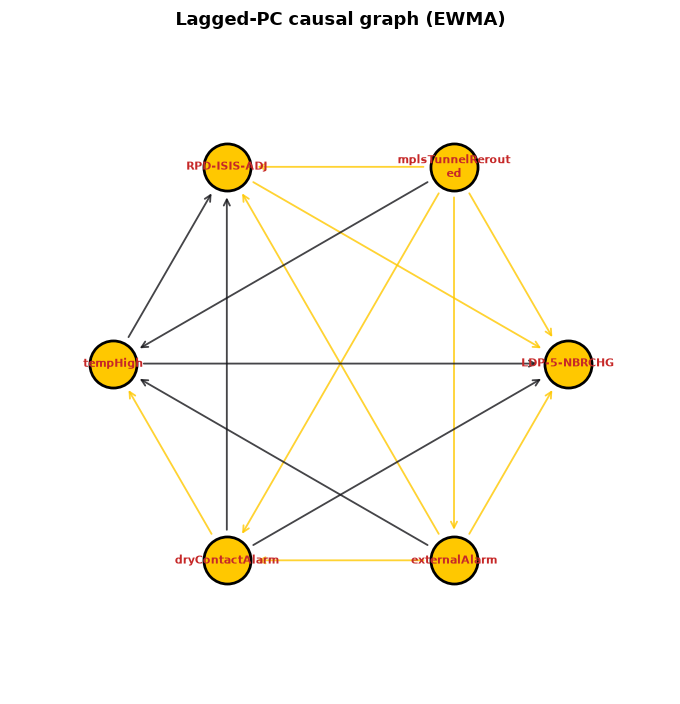

In [16]:
import textwrap

def draw_graph(graph):
    ids = [node["id"] for node in graph["nodes"]]
    if not ids:
        print("graph is empty")
        return

    angles = np.linspace(0, 2 * math.pi, len(ids), endpoint=False)
    pos = {node_id: (math.cos(a), math.sin(a)) for node_id, a in zip(ids, angles)}

    fig, ax = plt.subplots(figsize=(10, 6.5))

    for edge in graph["edges"]:
        x1, y1 = pos[edge["from"]]
        x2, y2 = pos[edge["to"]]
        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(
                arrowstyle="->",
                lw=1.2,
                color=C_ALT if edge["causal_power"] >= 0.5 else C_MAIN,
                alpha=0.8,
                shrinkA=20,
                shrinkB=20,
            ),
            zorder=1,
        )

    for node_id, (x, y) in pos.items():
        ax.scatter(
            [x], [y],
            s=950,
            facecolor=C_ALT,       # жёлтый
            edgecolor="black",
            linewidth=1.8,
            zorder=3,
        )

        # короткая подпись ВНУТРИ кружка, чёрным по жёлтому
        label = node_id.split("|")[-1] or "?"
        label = textwrap.fill(label, width=16)

        ax.text(
            x, y, label,
            ha="center", va="center",
            fontsize=7,
            fontweight="bold",
            color=C_WARN,
            zorder=4,
        )

    ax.set_title("Lagged-PC causal graph (EWMA)")
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


draw_graph(graph)

## 7. Кластеризация микро-штормов

HDBSCAN/KMeans работают по признакам ряда: активность, peak intensity, EWMA area,
bursts, число устройств. В ноутбуке принудительно используем KMeans, чтобы
результат был детерминированным; в API по умолчанию стоит HDBSCAN с fallback.


method: kmeans | clusters: 3 | noise: 0


,label,size,systems,peak_ewma,anomaly_score,is_micro_storm
0,micro_storm_1,2,"[alu, nokia]",2.0,0.5161,True
1,micro_storm_2,1,[power],1.0,0.4941,False
2,micro_storm_0,3,"[Cisco, Huawei NE-Series, Juniper]",3.0,0.4124,True


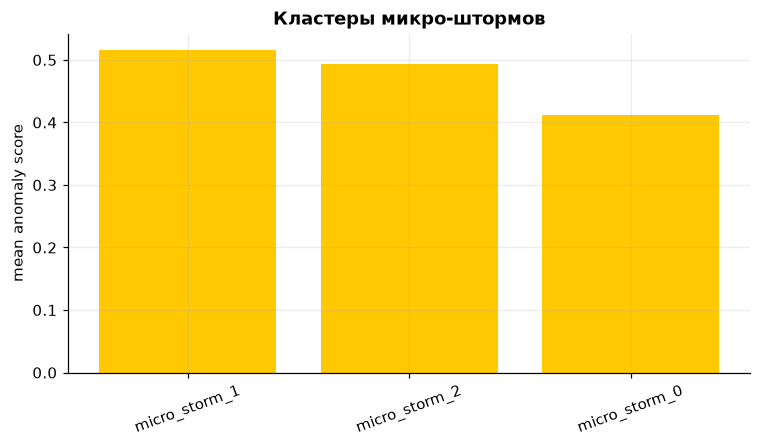

,check,status,detail
0,Kafka/ClickHouse без потерь,PASS,480 rows
1,Интенсивность: нули в дыре,PASS,18 bins
2,EWMA: сглаживание не превышает пик,PASS,max=3.000
3,Causal graph: DAG + найденный лид,PASS,"15 edges, DAG ok"
4,Кластеризация: микро-штормы,PASS,3 clusters


In [8]:
clusters = cluster_series(prepared, ClusterConfig(method="kmeans", n_clusters=3, top_k=20))
cluster_rows = pd.DataFrame(clusters["clusters"])
print("method:", clusters["method_used"], "| clusters:", len(cluster_rows),
      "| noise:", len(clusters["noise"]))
display(cluster_rows[["label", "size", "systems", "peak_ewma", "anomaly_score", "is_micro_storm"]])
assert clusters["clusters"], "clusters must not be empty"
check("Кластеризация: микро-штормы", lambda: f"{len(clusters['clusters'])} clusters")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cluster_rows["label"], cluster_rows["anomaly_score"], color=C_ALT)
ax.set_ylabel("mean anomaly score")
ax.set_title("Кластеры микро-штормов")
plt.xticks(rotation=20)
plt.show()
display(pd.DataFrame(CHECKS))


## 8. Runbook-оркестратор

Проверяем сквозной сценарий: граф → XGBoost/эвристика → runbook registry →
структурированные шаги для инженера. Модель пока cold-start, поэтому
`model_kind=heuristic`; после feedback она заменяется на XGBoost.


In [9]:
ranker = PairRanker(RankerConfig(
    state_dir=Path(tempfile.mkdtemp(prefix="rt-ranker-")), auto_train=False))
registry = RunbookRegistry([
    dict(id="rb-A", system="Huawei NE-Series", alert_group="mplsTunnelRerouted",
         url="http://runbooks.local/mpls", steps=["check MPLS-TE tunnel state",
                                                   "verify IS-IS adjacency"],
         owner="ipcore"),
    dict(id="rb-B", system="Juniper", alert_group="RPD-ISIS-ADJ",
         url="http://runbooks.local/isis", steps=["check Juniper RPD logs",
                                                   "compare with MPLS reroute"],
         owner="ipcore"),
])
agent = RunbookAgent()
runbook = agent.generate(prepared, graph, clusters, ranker=ranker,
                         runbooks=registry, config=RunbookConfig(top_k=5))
print(runbook["summary"])
print("confidence:", runbook["confidence"], "| generated_by:", runbook["generated_by"])
display(pd.DataFrame(runbook["root_causes"]))
display(pd.DataFrame(runbook["steps"]))
assert runbook["root_causes"]
assert runbook["steps"]
check("Runbook: корни и шаги", lambda: f"{len(runbook['steps'])} steps, conf={runbook['confidence']}")
display(pd.DataFrame(CHECKS))


Наиболее вероятная первопричина: Juniper / RPD-ISIS-ADJ (p=1.00). Далее: Huawei NE-Series/mplsTunnelRerouted.
confidence: 0.9997 | generated_by: local-rules-v1


,node,system,integration,alert_group,probability,effects,evidence
0,ipcore|Juniper|RPD-ISIS-ADJ,Juniper,ipcore,RPD-ISIS-ADJ,0.9997,[ipcore|Cisco|LDP-5-NBRCHG],"[{'from_': 'ipcore|Juniper|RPD-ISIS-ADJ', 'to'..."
1,ipcore|Huawei NE-Series|mplsTunnelRerouted,Huawei NE-Series,ipcore,mplsTunnelRerouted,0.9992,"[ipcore|Cisco|LDP-5-NBRCHG, ipcore|Juniper|RPD...",[{'from_': 'ipcore|Huawei NE-Series|mplsTunnel...


,order,action,source,runbook_id
0,1,check Juniper RPD logs,runbook:rb-B,rb-B
1,2,compare with MPLS reroute,runbook:rb-B,rb-B
2,3,check MPLS-TE tunnel state,runbook:rb-A,rb-A
3,4,verify IS-IS adjacency,runbook:rb-A,rb-A
4,5,"Проверить Juniper / RPD-ISIS-ADJ: 131 событий,...",generated,NaN
5,6,Сверить с CMDB-топологией и соседними узлами; ...,generated,NaN
6,7,Проверить Huawei NE-Series / mplsTunnelReroute...,generated,NaN
7,8,Сверить с CMDB-топологией и соседними узлами; ...,generated,NaN


,check,status,detail
0,Kafka/ClickHouse без потерь,PASS,480 rows
1,Интенсивность: нули в дыре,PASS,18 bins
2,EWMA: сглаживание не превышает пик,PASS,max=3.000
3,Causal graph: DAG + найденный лид,PASS,"15 edges, DAG ok"
4,Кластеризация: микро-штормы,PASS,3 clusters
5,Runbook: корни и шаги,PASS,"8 steps, conf=0.9997"


## 9. API: три эндпоинта на одном bundle

Запускаем FastAPI в тестовом режиме без синтетики и проверяем реальные
HTTP-контракты. Это одновременно smoke-тест роутинга, Pydantic-схем и
сериализации.


In [10]:
from fastapi.testclient import TestClient

tmp = Path(tempfile.mkdtemp(prefix="rt-api-"))
cfg = AppConfig(
    data_dir=tmp / "data", raw_dir=tmp / "data" / "raw",
    processed_dir=tmp / "data" / "processed", state_dir=tmp / "state",
    alarms_path=tmp / "data" / "processed" / "alarms.parquet",
    use_synthetic_when_empty=False,
)
body = bundle.model_dump(mode="json")
api_rows = []
with TestClient(create_app(cfg)) as client:
    for path, params in [
        ("/api/v1/topology/causal-graph", dict(max_cond_size=0, remove_common_factor=False)),
        ("/api/v1/anomalies/clusters", dict(method="kmeans", n_clusters=3)),
        ("/api/v1/agent/runbook", dict(max_cond_size=0, top_k=5)),
    ]:
        t0 = time.perf_counter()
        response = client.post(path, params=params, json=body)
        api_rows.append(dict(endpoint=path, status=response.status_code,
                             ms=round((time.perf_counter() - t0) * 1000, 1),
                             keys=", ".join(list(response.json())[:5])))
        assert response.status_code == 200, response.text
api_df = pd.DataFrame(api_rows)
display(api_df)
check("API: 3 realtime endpoint", lambda: f"{len(api_df)} routes, all 200")
display(pd.DataFrame(CHECKS))


,endpoint,status,ms,keys
0,/api/v1/topology/causal-graph,200,256.1,"incident_id, nodes, edges, topological_order, ..."
1,/api/v1/anomalies/clusters,200,112.2,"incident_id, series_total, clusters, noise, me..."
2,/api/v1/agent/runbook,200,188.8,"incident_id, summary, confidence, root_causes,..."


,check,status,detail
0,Kafka/ClickHouse без потерь,PASS,480 rows
1,Интенсивность: нули в дыре,PASS,18 bins
2,EWMA: сглаживание не превышает пик,PASS,max=3.000
3,Causal graph: DAG + найденный лид,PASS,"15 edges, DAG ok"
4,Кластеризация: микро-штормы,PASS,3 clusters
5,Runbook: корни и шаги,PASS,"8 steps, conf=0.9997"
6,API: 3 realtime endpoint,PASS,"3 routes, all 200"


## 10. Lambda-архитектура: цена горячего пути

Симулируем рост размера инцидента и измеряем полный hot-path: подготовка
интенсивности/EWMA + causal graph + кластеризация. Это не benchmark production,
но показывает, где появятся ограничения и зачем нужен ClickHouse.


,alarms,series,bins,edges,clusters,ms
0,200,6,181,15,3,129.9
1,500,6,181,15,3,119.8
2,1000,6,181,15,3,121.1
3,480,6,181,15,3,139.7


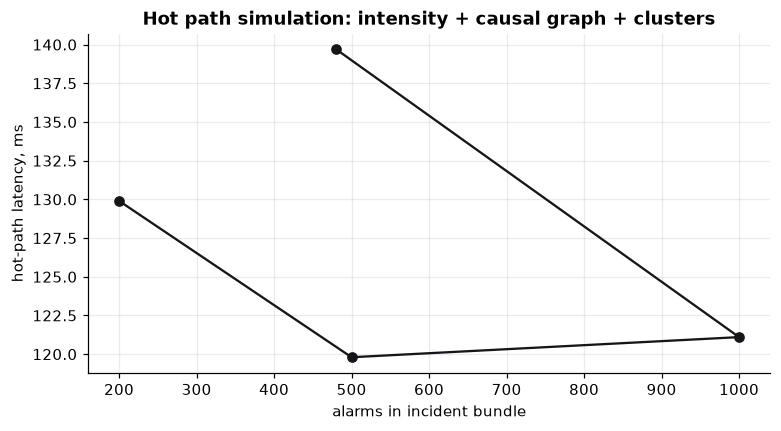

In [11]:
latency = []
for n in [200, 500, 1000, len(stream_gap)]:
    subset = stream_gap.head(n)
    b = bundle_from_frame(subset, incident_id=f"INC-LAT-{n}")
    t0 = time.perf_counter()
    p = prepare_incident(b, step_seconds=STEP, ewma_half_life_seconds=30)
    g = build_causal_graph(p, causal_cfg)
    c = cluster_series(p, ClusterConfig(method="kmeans", n_clusters=3))
    latency.append(dict(alarms=n, series=len(p.keys), bins=len(p.grid),
                        edges=len(g["edges"]), clusters=len(c["clusters"]),
                        ms=round((time.perf_counter() - t0) * 1000, 1)))
latency_df = pd.DataFrame(latency)
display(latency_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(latency_df["alarms"], latency_df["ms"], marker="o", color=C_MAIN)
ax.set_xlabel("alarms in incident bundle")
ax.set_ylabel("hot-path latency, ms")
ax.set_title("Hot path simulation: intensity + causal graph + clusters")
plt.show()


## 11. Выводы и ограничения

**Что проверено.**

- интенсивность корректно заполняет дыры нулями, а EWMA сглаживает разрыв;
- симулятор Kafka/ClickHouse не теряет события и отдаёт контракт, пригодный для
  `prepare_incident`;
- causal graph строит DAG и находит посаженный лид;
- кластеризация выделяет микро-штормы;
- runbook использует XGBoost/эвристику и runbook registry;
- все три API-эндпоинта отвечают `200` на одном и том же bundle;
- hot path масштабируется предсказуемо на синтетическом окне.

**Что осталось production-задачей.**

1. Заменить `MiniKafka`/`MiniClickHouse` на реальные Kafka/Vector и ClickHouse;
   SQL-заготовка есть в `docs/REALTIME.md`.
2. Для causal graph подключить CausalNex/DoWhy или оставить lagged-PC, но
   валидировать на размеченных инцидентах Netcool.
3. Для LLM включить маскировку NDA-полей и внешний orchestrator; текущий
   `RunbookAgent` уже принимает `llm`-функцию.
4. Для XGBoost собрать feedback с кнопок «находка / спам» и переобучать по
   микро-батчам; сейчас в ноутбуке cold-start эвристика.
5. Для продакшена нужны аутентификация, лимиты, TTL горячего хранилища,
   очередь фоновых переобучений и мониторинг дрейфа.
